# Refresca SP — previsão da temperatura máxima do dia seguinte
**Global Solution · Inteligência Artificial & Machine Learning**

**Pergunta:** usando somente observações disponíveis até o encerramento do dia D,
conseguimos prever a temperatura máxima de D+1 na estação INMET A701 (São Paulo — Mirante)?

**Escopo:** experimento isolado; nenhuma API, app ou sensor é conectado. Dados reais são obrigatórios.
Random Forest para regressão, baseline de persistência, validação temporal e teste final em 2025.
O indicador de dia muito quente usa 35 °C como **regra didática previamente fixada**, não como
limiar oficial ou diagnóstico de risco de saúde. Um dia quente não caracteriza sozinho onda de calor.

**Estado deste arquivo:** treinamento executado no Colab; saídas das etapas científicas preservadas.
A revisão final atualizou instalação, upload opcional e documentação, sem retreinar o modelo.
As células utilitárias alteradas estão sem contagem de execução; os resultados existentes correspondem
à execução registrada em `resultados/configuracao.json`.

| Integrante | RM |
|---|---|
| Matheus | 555177 |
| Gustavo A. | 559098 |
| Nicolas | 556617 |
| Gustavo C. | 556289 |
| Igor Soos | 556010 |

**Como usar:** no Colab, abra este `.ipynb`, execute em ordem (CPU basta). A primeira célula instala
as dependências. A pasta `ml/` será criada no diretório atual quando necessário. Se baixar os CSVs
manualmente, coloque os arquivos originais de A701 dos anos 2021–2025 em `ml/dados/brutos/`.

**Colab:** use uma sessão limpa se já houve conflito de dependências. A instalação final não altera
o IPython. Se o Colab solicitar reinício após a instalação, reinicie a sessão e prossiga pela seção 1.
As saídas salvas podem ser lidas sem executar novamente.


In [ ]:
# Mantém o IPython gerenciado pelo Colab. Versões numéricas da execução registrada.
%pip install -q "numpy==2.4.6" "pandas==2.2.3" "scikit-learn==1.6.1" "matplotlib>=3.8,<4" "joblib>=1.3,<2"

## 1. Configuração e protocolo definido antes dos resultados

- Fonte: [INMET — Dados históricos anuais](https://portal.inmet.gov.br/dadoshistoricos).
- Estação: A701, São Paulo — Mirante; verificar identificação nos cabeçalhos originais.
- Dados: 2021–2025. Treino: alvos anteriores a 2025; teste: alvos de 2025, com expurgo na fronteira.
- Três validações cronológicas no treino: primeiro semestre de 2023, segundo semestre de 2023 e 2024.
- Busca: **12 combinações de 3 hiperparâmetros**, selecionadas pelo menor MAE médio na validação.
- Horizonte: um dia. Previsão emitida após encerrar D, assumindo dados já disponíveis.
- Fuso: America/Sao_Paulo. A máxima horária corresponde à hora anterior ao registro;
  o registro de 03:00 UTC é associado à última hora do dia local anterior.
- Qualidade: alvo e máxima de D exigem 24 máximas horárias válidas. Não interpolamos o alvo.
- Teste em modo retrospectivo de um passo: ao prever cada dia, o dia anterior já foi observado.
  Não é uma previsão de todo o ano feita em janeiro.

In [5]:
from pathlib import Path
import io, json, hashlib, zipfile, urllib.request, shutil, unicodedata, re, sys
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, joblib
from IPython.display import display
from sklearn.ensemble import RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, ParameterGrid
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, confusion_matrix

BASE = Path.cwd() if Path.cwd().name == 'ml' else Path.cwd() / 'ml'
BRUTOS = BASE / 'dados' / 'brutos'
FIG = BASE / 'figuras'
RES = BASE / 'resultados'
for pasta in [BRUTOS, FIG, RES]: pasta.mkdir(parents=True, exist_ok=True)
ANOS = list(range(2021, 2026))
ESTACAO = 'A701'
LIMIAR = 35.0
SEED = 42
FUSO = 'America/Sao_Paulo'
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .2})
print('Diretório:', BASE)
print('Python:', sys.version.split()[0], '| pandas:', pd.__version__, '| sklearn:', sklearn.__version__)

Diretório: /content/ml
Python: 3.13.18 | pandas: 2.2.3 | sklearn: 1.6.1


## 2. Obtenção e rastreabilidade
Os ZIPs nacionais podem ser grandes. O código mantém somente o CSV de A701 de cada ano.
Não substitui falhas de download por dados simulados. O manifesto registra URL, arquivo e SHA-256.

**Alternativa manual:** abra o portal, baixe os ZIPs de 2021 a 2025, extraia de cada um somente o
CSV cujo nome contém `_A701_` e envie para `ml/dados/brutos/`, preservando os nomes originais.
Em seguida execute novamente esta célula. Se houver indisponibilidade, aguarde ou use o navegador;
não mude de estação nem de período silenciosamente.

**Pacote final:** os cinco CSVs já estão em `dados/brutos/`. Em execução local, o upload é ignorado.
No Colab, envie-os na célula opcional abaixo; abrir o notebook não envia os arquivos junto.
Os nomes `(1)` vistos nas saídas originais são cópias do upload; o pacote usa os nomes originais,
com conteúdo idêntico confirmado por SHA-256.


In [ ]:
# No Colab, envie os CSVs apenas quando ainda não estiverem presentes.
def tem_csv(ano):
    return any(p.is_file() and p.suffix.lower() == '.csv'
               and f'_{ESTACAO}_' in p.name.upper() and str(ano) in p.name
               for p in BRUTOS.rglob('*'))
faltantes = [ano for ano in ANOS if not tem_csv(ano)]
if faltantes:
    try:
        from google.colab import files
    except ImportError:
        print('CSV(s) ausente(s):', faltantes, '— a próxima célula tentará o download oficial.')
    else:
        print('Selecione somente os CSVs A701 dos anos ausentes:', faltantes)
        enviados = files.upload()
        for nome, conteudo in enviados.items():
            if Path(nome).suffix.lower() != '.csv' or f'_{ESTACAO}_' not in nome.upper():
                raise ValueError(f'Arquivo inesperado: {nome}. Envie CSVs da estação A701.')
            destino = BRUTOS / Path(nome).name
            destino.write_bytes(conteudo)
            print('Salvo:', destino.name)
else:
    print('Os cinco CSVs já estão disponíveis; upload dispensado.')

In [8]:
def arquivos_ano(ano):
    return [p for p in BRUTOS.rglob('*') if p.is_file() and p.suffix.lower() == '.csv'
            and f'_{ESTACAO}_' in p.name.upper() and str(ano) in p.name]

manifesto = []
for ano in ANOS:
    url = f'https://portal.inmet.gov.br/uploads/dadoshistoricos/{ano}.zip'
    locais = arquivos_ano(ano)
    origem = 'CSV local; confirmar origem oficial'
    if not locais:
        pacote = BRUTOS / f'{ano}.zip'
        try:
            print(f'Baixando {ano}...')
            with urllib.request.urlopen(url, timeout=120) as resposta, pacote.open('wb') as destino:
                shutil.copyfileobj(resposta, destino)
            with zipfile.ZipFile(pacote) as z:
                nomes = [n for n in z.namelist() if f'_{ESTACAO}_' in n.upper() and n.lower().endswith('.csv')]
                if len(nomes) != 1:
                    raise ValueError(f'Esperado um CSV A701 em {ano}; encontrados: {nomes}')
                destino = BRUTOS / Path(nomes[0]).name
                destino.write_bytes(z.read(nomes[0]))
            locais = [destino]
            origem = 'download direto INMET'
        except Exception as exc:
            raise RuntimeError(f'Não foi possível obter {ano}: {exc}. Baixe o CSV A701 pelo portal e coloque em {BRUTOS}.') from exc
        finally:
            pacote.unlink(missing_ok=True)
    if len(locais) != 1:
        raise ValueError(f'Mais de um CSV de {ano}: remova as cópias duplicadas: {locais}')
    p = locais[0]
    manifesto.append({'ano': ano, 'estacao': ESTACAO, 'url': url, 'arquivo': p.name,
                      'origem': origem, 'sha256': hashlib.sha256(p.read_bytes()).hexdigest(),
                      'verificado_em_utc': datetime.now(timezone.utc).isoformat()})
(RES / 'manifesto_fontes.json').write_text(json.dumps(manifesto, indent=2, ensure_ascii=False), encoding='utf-8')
display(pd.DataFrame(manifesto)[['ano', 'estacao', 'arquivo', 'origem']])

,ano,estacao,arquivo,origem
0,2021,A701,INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-202...,CSV local; confirmar origem oficial
1,2022,A701,INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-202...,CSV local; confirmar origem oficial
2,2023,A701,INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-202...,CSV local; confirmar origem oficial
3,2024,A701,INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-202...,CSV local; confirmar origem oficial
4,2025,A701,INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-202...,CSV local; confirmar origem oficial


## 3. Leitura, limpeza e qualidade
O leitor procura a linha de cabeçalho, interpreta `;` e vírgula decimal, identifica ausências
(`-9999` ou campos vazios) e verifica o código A701. Valores fora de limites amplos de plausibilidade
são marcados como ausentes, nunca trocados por valores inventados. Conflitos em horários duplicados
interrompem o processo. O relatório de qualidade mostra perdas por ano e variável.

In [10]:
def normalizar(s):
    return unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode().upper().strip()

def ler_csv(p):
    raw = p.read_bytes()
    try: texto = raw.decode('utf-8-sig')
    except UnicodeDecodeError: texto = raw.decode('latin-1')
    linhas = texto.splitlines()
    # O cabeçalho verdadeiro precisa conter as colunas DATA e HORA.
    cab = next(
        (
            i
            for i, linha in enumerate(linhas)
            if normalizar(linha.split(';')[0]).startswith('DATA')
            and any(
                normalizar(campo).startswith('HORA')
                for campo in linha.split(';')
            )
        ),
        None
    )
    if cab is None: raise ValueError(f'Cabeçalho não encontrado: {p.name}')
    meta = '\n'.join(linhas[:cab])
    if ESTACAO not in meta.upper(): raise ValueError(f'Estação diferente de {ESTACAO}: {p.name}')
    print(p.name, '\n', meta)
    df = pd.read_csv(io.StringIO('\n'.join(linhas[cab:])), sep=';', dtype=str)
    def coluna(prefixo):
        candidatas = [c for c in df.columns if normalizar(c).startswith(prefixo)]
        if len(candidatas) != 1: raise ValueError(f'Coluna {prefixo}: {candidatas}')
        return candidatas[0]
    datas_texto = df[coluna('DATA')].str.strip()

    data = pd.Series(pd.NaT, index=df.index, dtype='datetime64[ns]')

    for formato in ['%Y/%m/%d', '%Y-%m-%d', '%d/%m/%Y', '%d-%m-%Y']:
        convertidas = pd.to_datetime(
            datas_texto,
            format=formato,
            errors='coerce'
        )
        data = data.fillna(convertidas)

    if data.isna().any():
        exemplos = datas_texto[data.isna()].head().tolist()
        raise ValueError(f'Datas não reconhecidas em {p.name}: {exemplos}')
    hora = df[coluna('HORA')].str.extract(r'^(\d{2})', expand=False)
    ts = pd.to_datetime(data.dt.strftime('%Y-%m-%d') + ' ' + hora + ':00', utc=True, errors='coerce')
    if ts.isna().any(): raise ValueError(f'Datas/horas inválidas em {p.name}')
    saida = pd.DataFrame({'timestamp': ts})
    for nome, prefixo in {'tmax_h':'TEMPERATURA MAXIMA NA HORA ANT.',
                         'temp':'TEMPERATURA DO AR - BULBO SECO',
                         'umidade':'UMIDADE RELATIVA DO AR, HORARIA',
                         'pressao':'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA',
                         'vento':'VENTO, VELOCIDADE HORARIA'}.items():
        saida[nome] = pd.to_numeric(df[coluna(prefixo)].str.replace(',', '.', regex=False), errors='coerce')
    return saida

horario = pd.concat([ler_csv(arquivos_ano(a)[0]) for a in ANOS], ignore_index=True)
cols = ['tmax_h', 'temp', 'umidade', 'pressao', 'vento']
duplicatas = int(horario.duplicated('timestamp').sum())
conflitos = horario.groupby('timestamp')[cols].nunique(dropna=False).gt(1).any(axis=1)
if conflitos.any(): raise ValueError('Horários repetidos com valores divergentes; verificar fontes.')
horario = horario.drop_duplicates('timestamp').sort_values('timestamp').set_index('timestamp')
limites = {'tmax_h':(-10, 50), 'temp':(-10, 50), 'umidade':(0, 100), 'pressao':(800, 1100), 'vento':(0, 60)}
invalidos = {}
for col, (baixo, alto) in limites.items():
    fora = horario[col].notna() & ~horario[col].between(baixo, alto)
    invalidos[col] = int(fora.sum())
    horario.loc[fora, col] = np.nan
print('Duplicatas idênticas removidas:', duplicatas, '| Valores fora dos limites:', invalidos)
display(horario[cols].isna().mean().rename('fracao_ausente'))
# A máxima horária refere-se à hora anterior. O instante final pertence ao intervalo que terminou.
horario['dia'] = (horario.index - pd.Timedelta(nanoseconds=1)).tz_convert(FUSO).normalize().tz_localize(None)
g = horario.groupby('dia')
diario = g.agg(tmax=('tmax_h', 'max'), temp_media=('temp', 'mean'),
                umidade_media=('umidade', 'mean'), pressao_media=('pressao', 'mean'),
                vento_medio=('vento', 'mean'), horas_max=('tmax_h', 'count'))
# Grade diária completa: shift(1) deve representar um dia de calendário, nunca o próximo dia disponível.
diario = diario.reindex(pd.date_range('2021-01-01', '2025-12-31', freq='D'))
diario.index.name = 'dia'
diario.loc[diario['horas_max'] != 24, 'tmax'] = np.nan
for origem, destino in [('temp','temp_media'), ('umidade','umidade_media'),
                        ('pressao','pressao_media'), ('vento','vento_medio')]:
    contagem = g[origem].count().reindex(diario.index)
    diario.loc[contagem < 20, destino] = np.nan
qualidade = diario.groupby(diario.index.year).agg(dias=('horas_max','size'), dias_com_tmax=('tmax','count'))
qualidade['cobertura_tmax_pct'] = 100 * qualidade.dias_com_tmax / qualidade.dias
qualidade.to_csv(RES / 'qualidade_por_ano.csv')
diario.to_csv(BASE / 'dados' / 'diario_A701.csv')
display(qualidade)
print('Último dia pode ficar incompleto: o ZIP seguinte não está incluído.')

INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2021_A_31-12-2021 (1).CSV 
 REGIAO:;SE
UF:;SP
ESTACAO:;SAO PAULO - MIRANTE
CODIGO (WMO):;A701
LATITUDE:;-23,496294
LONGITUDE:;-46,620088
ALTITUDE:;785,64
DATA DE FUNDACAO:;25/07/06
INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2022_A_31-12-2022 (1).CSV 
 REGIAO:;SE
UF:;SP
ESTACAO:;SAO PAULO - MIRANTE
CODIGO (WMO):;A701
LATITUDE:;-23,49638888
LONGITUDE:;-46,61999999
ALTITUDE:;785,64
DATA DE FUNDACAO:;25/07/06
INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2023_A_31-12-2023 (1).CSV 
 REGIAO:;SE
UF:;SP
ESTACAO:;SAO PAULO - MIRANTE
CODIGO (WMO):;A701
LATITUDE:;-23,49638888
LONGITUDE:;-46,61999999
ALTITUDE:;785,64
DATA DE FUNDACAO:;25/07/06
INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2024_A_31-12-2024 (1).CSV 
 REGIAO:;SE
UF:;SP
ESTACAO:;SAO PAULO - MIRANTE
CODIGO (WMO):;A701
LATITUDE:;-23,49638888
LONGITUDE:;-46,61999999
ALTITUDE:;785,64
DATA DE FUNDACAO:;25/07/06
INMET_SE_SP_A701_SAO PAULO - MIRANTE_01-01-2025_A_31-12-2025 (1).CSV 
 REGIAO:;SE
UF:;SP
EST

,fracao_ausente
tmax_h,0.006458
temp,0.006366
umidade,0.006389
pressao,0.006366
vento,0.006412


,dias,dias_com_tmax,cobertura_tmax_pct
dia,,,
2021,365,364,99.726027
2022,365,365,100.000000
2023,365,314,86.027397
2024,366,355,96.994536
2025,365,332,90.958904


Último dia pode ficar incompleto: o ZIP seguinte não está incluído.


## 4. Atributos e alvo sem vazamento
Cada linha é o dia de observação D. O alvo é `tmax(D+1)`. Entradas: máxima e médias de D,
máximas de D−1, D−2 e D−7, médias móveis terminando em D e sazonalidade de D+1 (calendário conhecido).
A grade diária é preservada antes dos deslocamentos. Não usamos médias centradas, `bfill`
ou informações meteorológicas do futuro. O preenchimento das entradas faltantes será aprendido
dentro de cada fold, somente no treino. O alvo nunca é imputado.

Treino: 1351 alvos 2021-01-02 00:00:00 a 2024-12-30 00:00:00
Teste: 303 alvos 2025-01-01 00:00:00 a 2025-12-30 00:00:00
Atributos: ['tmax', 'temp_media', 'umidade_media', 'pressao_media', 'vento_medio', 'tmax_lag1', 'tmax_lag2', 'tmax_lag7', 'tmax_media3', 'tmax_media7', 'ano_seno', 'ano_cosseno']


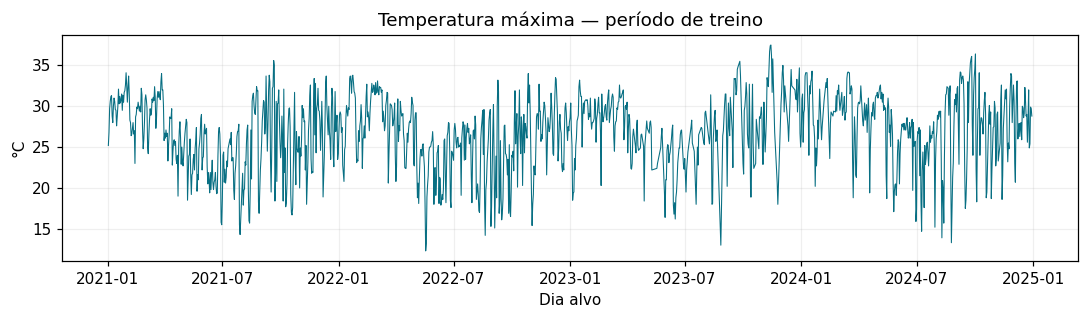

In [11]:
features = diario[['tmax', 'temp_media', 'umidade_media', 'pressao_media', 'vento_medio']].copy()
for lag in [1, 2, 7]: features[f'tmax_lag{lag}'] = diario.tmax.shift(lag)
for janela in [3, 7]: features[f'tmax_media{janela}'] = diario.tmax.rolling(janela, min_periods=janela).mean()
data_alvo = features.index + pd.Timedelta(days=1)
features['ano_seno'] = np.sin(2*np.pi*data_alvo.dayofyear/365.25)
features['ano_cosseno'] = np.cos(2*np.pi*data_alvo.dayofyear/365.25)
base = features.assign(alvo=diario.tmax.shift(-1), data_alvo=data_alvo)
base = base.loc[base.alvo.notna() & base.tmax.notna()].copy()
# Para o teste iniciar em 2025-01-01, sua origem é 2024-12-31.
# O último alvo do treino fica estritamente anterior à primeira origem do teste.
teste = base.loc[base.data_alvo.between('2025-01-01', '2025-12-31')].copy()
if teste.empty: raise ValueError('Nenhuma amostra de teste válida; verificar cobertura da estação.')
treino = base.loc[(base.data_alvo < '2025-01-01') & (base.data_alvo < teste.index.min())].copy()
if len(treino) < 500 or len(teste) < 100:
    raise ValueError(f'Cobertura insuficiente para este protocolo: treino={len(treino)}, teste={len(teste)}. Investigue a qualidade antes de prosseguir.')
Xtr, ytr = treino[features.columns], treino.alvo
Xte, yte = teste[features.columns], teste.alvo
assert treino.data_alvo.max() < teste.index.min()
assert not Xtr.index.intersection(Xte.index).size
print('Treino:', len(treino), 'alvos', treino.data_alvo.min(), 'a', treino.data_alvo.max())
print('Teste:', len(teste), 'alvos', teste.data_alvo.min(), 'a', teste.data_alvo.max())
print('Atributos:', list(features.columns))
base.to_csv(BASE / 'dados' / 'base_modelagem.csv')
# Exploração restrita ao treino: o teste não orienta escolhas.
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(treino.data_alvo, ytr, linewidth=.7, color='#086f83')
ax.set(title='Temperatura máxima — período de treino', ylabel='°C', xlabel='Dia alvo')
fig.tight_layout(); fig.savefig(FIG/'01_serie_treino.png'); plt.show()

## 5. Random Forest e busca de hiperparâmetros
A floresta combina árvores e captura relações não lineares em dados tabulares, sem exigir
padronização das escalas. É adequada como primeiro modelo, mas tem dificuldade de extrapolar
extremos além dos observados no treino.

Testamos `n_estimators` = 100/200; `max_depth` = 4/8/None; `min_samples_leaf` = 2/5:
**2 × 3 × 2 = 12 combinações**, cada uma em 3 folds temporais (36 ajustes + refit).
Usamos folds de calendário explícitos porque a remoção de dias inválidos torna os intervalos
entre amostras irregulares. O alvo de cada treino termina antes da primeira data de origem da validação.

In [12]:
folds, descricoes = [], []
for inicio, fim in [('2023-01-01','2023-07-01'), ('2023-07-01','2024-01-01'), ('2024-01-01','2025-01-01')]:
    va = np.flatnonzero((treino.data_alvo >= inicio) & (treino.data_alvo < fim))
    if len(va) < 30: raise ValueError(f'Poucos dados de validação em {inicio}: {len(va)}')
    tr = np.flatnonzero(treino.data_alvo < treino.index[va].min())
    if len(tr) < 200: raise ValueError('Histórico insuficiente no fold.')
    assert treino.data_alvo.iloc[tr].max() < treino.index[va].min()
    folds.append((tr, va))
    descricoes.append({'fold':len(folds), 'n_treino':len(tr), 'n_validacao':len(va),
        'ultimo_alvo_treino':str(treino.data_alvo.iloc[tr].max().date()),
        'primeira_origem_validacao':str(treino.index[va].min().date()),
        'ultimo_alvo_validacao':str(treino.data_alvo.iloc[va].max().date())})
display(pd.DataFrame(descricoes))
pd.DataFrame(descricoes).to_csv(RES/'folds.csv', index=False)
pipe = Pipeline([('imputer', SimpleImputer(strategy='median', add_indicator=True, keep_empty_features=True)),
                 ('rf', RandomForestRegressor(random_state=SEED, n_jobs=1))])
grade = {'rf__n_estimators':[100,200], 'rf__max_depth':[4,8,None], 'rf__min_samples_leaf':[2,5]}
assert len(list(ParameterGrid(grade))) == 12
busca = GridSearchCV(pipe, grade, scoring='neg_mean_absolute_error', cv=folds,
                     n_jobs=2, return_train_score=True, error_score='raise', verbose=1)
busca.fit(Xtr, ytr)
modelo = busca.best_estimator_
cv = pd.DataFrame(busca.cv_results_)
cv['MAE_validacao'] = -cv.mean_test_score
cv['MAE_treino_folds'] = -cv.mean_train_score
cv.to_csv(RES/'busca_hiperparametros.csv', index=False)
display(cv[['params','MAE_treino_folds','MAE_validacao','std_test_score']].sort_values('MAE_validacao'))
print('Melhores parâmetros:', busca.best_params_)
print('MAE médio na validação:', -busca.best_score_)
# Comparador simples no mesmo protocolo de validação: amanhã = hoje.
mae_baseline_cv = np.mean([mean_absolute_error(ytr.iloc[v], Xtr.tmax.iloc[v]) for _, v in folds])
print('MAE de persistência na validação:', mae_baseline_cv)

,fold,n_treino,n_validacao,ultimo_alvo_treino,primeira_origem_validacao,ultimo_alvo_validacao
0,1,726,155,2022-12-30,2022-12-31,2023-06-30
1,2,881,126,2023-06-29,2023-06-30,2023-12-31
2,3,1007,343,2023-12-30,2023-12-31,2024-12-30


Fitting 3 folds for each of 12 candidates, totalling 36 fits


,params,MAE_treino_folds,MAE_validacao,std_test_score
11,"{'rf__max_depth': None, 'rf__min_samples_leaf'...",1.389195,2.352154,0.537316
7,"{'rf__max_depth': 8, 'rf__min_samples_leaf': 5...",1.489634,2.353053,0.532076
6,"{'rf__max_depth': 8, 'rf__min_samples_leaf': 5...",1.496229,2.359955,0.544028
10,"{'rf__max_depth': None, 'rf__min_samples_leaf'...",1.397895,2.360525,0.547652
5,"{'rf__max_depth': 8, 'rf__min_samples_leaf': 2...",1.311736,2.365012,0.535046
9,"{'rf__max_depth': None, 'rf__min_samples_leaf'...",0.955861,2.370156,0.543268
4,"{'rf__max_depth': 8, 'rf__min_samples_leaf': 2...",1.316535,2.378804,0.541389
8,"{'rf__max_depth': None, 'rf__min_samples_leaf'...",0.965228,2.380807,0.550118
3,"{'rf__max_depth': 4, 'rf__min_samples_leaf': 5...",1.971596,2.394110,0.551708
2,"{'rf__max_depth': 4, 'rf__min_samples_leaf': 5...",1.974041,2.401975,0.557912


Melhores parâmetros: {'rf__max_depth': None, 'rf__min_samples_leaf': 5, 'rf__n_estimators': 200}
MAE médio na validação: 2.352153690370587
MAE de persistência na validação: 2.3680625306958425


## 6. Avaliação final — treino e teste lado a lado
**MAE**: erro absoluto médio em °C. **RMSE**: penaliza mais os erros grandes.
**R²**: comparação com a média observada; pode ser negativo. Nenhuma dessas métricas é uma
“porcentagem de acerto de temperatura”. Persistência prevê que a máxima de amanhã será igual à de hoje.
A avaliação do treino é in-sample; a validação temporal estima a generalização durante a seleção.
Não reajustar hiperparâmetros após olhar o teste.

,modelo,conjunto,MAE_C,RMSE_C,R2
0,Random Forest,Treino,1.403,1.973,0.803
1,Persistência,Treino,2.420,3.439,0.402
2,Random Forest,Teste,2.295,3.050,0.556
3,Persistência,Teste,2.543,3.528,0.407


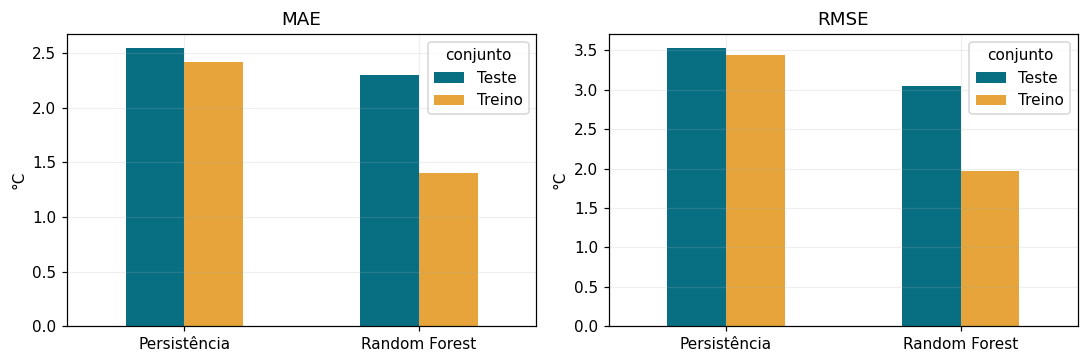

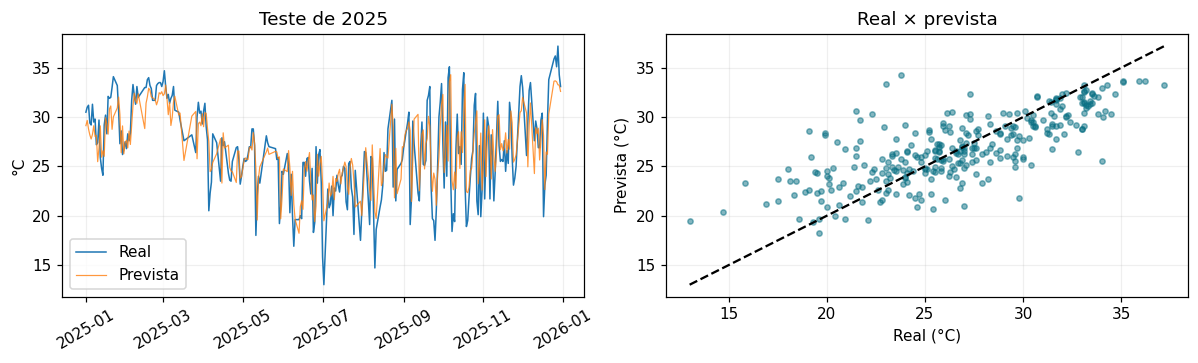

In [13]:
pred_tr = modelo.predict(Xtr)
pred_te = modelo.predict(Xte)
def metricas(y, pred):
    return {'MAE_C':mean_absolute_error(y,pred), 'RMSE_C':np.sqrt(mean_squared_error(y,pred)), 'R2':r2_score(y,pred)}
linhas = []
for nome, yt, pr, persist in [('Treino', ytr, pred_tr, Xtr.tmax), ('Teste', yte, pred_te, Xte.tmax)]:
    for estimador, previsao in [('Random Forest',pr), ('Persistência',persist)]:
        linhas.append({'modelo':estimador, 'conjunto':nome, **metricas(yt,previsao)})
metricas_df = pd.DataFrame(linhas)
metricas_df.to_csv(RES/'metricas.csv', index=False)
display(metricas_df.round(3))
predicoes = pd.DataFrame({'data_origem':teste.index, 'data_alvo':teste.data_alvo.values,
                         'real_C':yte.values, 'previsto_C':pred_te, 'persistencia_C':Xte.tmax.values})
predicoes['erro_C'] = predicoes.previsto_C - predicoes.real_C
predicoes.to_csv(RES/'predicoes_teste.csv', index=False)
fig, axs = plt.subplots(1,2, figsize=(10,3.4))
for ax, met in zip(axs, ['MAE_C','RMSE_C']):
    metricas_df.pivot(index='modelo', columns='conjunto', values=met).plot.bar(ax=ax, rot=0, color=['#086f83','#e6a43a'])
    ax.set(title=met.replace('_C',''), ylabel='°C', xlabel='')
fig.tight_layout(); fig.savefig(FIG/'02_metricas.png'); plt.show()
fig, axs = plt.subplots(1,2, figsize=(11,3.4))
axs[0].plot(teste.data_alvo, yte, label='Real', lw=1)
axs[0].plot(teste.data_alvo, pred_te, label='Prevista', lw=.8, alpha=.8)
axs[0].set(title='Teste de 2025', ylabel='°C'); axs[0].legend(); axs[0].tick_params(axis='x', rotation=30)
axs[1].scatter(yte,pred_te,s=12,alpha=.5,color='#086f83')
lim=[min(yte.min(),pred_te.min()),max(yte.max(),pred_te.max())]
axs[1].plot(lim,lim,'k--'); axs[1].set(xlabel='Real (°C)',ylabel='Prevista (°C)',title='Real × prevista')
fig.tight_layout(); fig.savefig(FIG/'03_previsoes.png'); plt.show()

## 7. Indicador experimental de calor e erros relevantes ao cidadão
A regressão continua sendo o problema principal. Aplicamos a regra **máxima ≥ 35 °C** aos valores
reais e previstos, sem ajustar o limiar ao teste. Reportamos falsos negativos (dia muito quente sem
sinalização), falsos positivos e suporte. Se não houver eventos, recall é indefinido, não zero.
O limiar é apenas uma escolha didática; não representa alerta oficial ou probabilidade de risco.

**Resultado desta execução:** 5 dias reais ≥35 °C, nenhum alerta previsto, recall 0% e precisão
indefinida. O ganho na regressão não resultou em detecção eficaz desses extremos. São poucos eventos;
não extrapolamos essa taxa para outros períodos e não ajustamos o limiar usando o teste.


{
  "limiar_didatico_C": 35.0,
  "dias_quentes_reais": 5,
  "TN": 298,
  "FP": 0,
  "FN": 5,
  "TP": 0,
  "recall": 0.0,
  "precisao": null,
  "MAE_dias_quentes_C": 2.3401470746135544
}


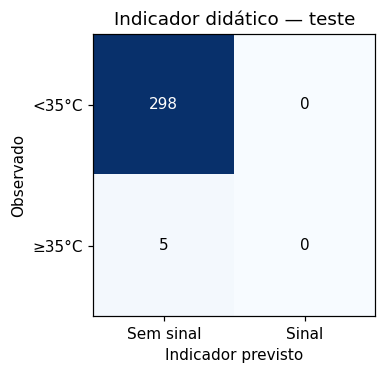

In [14]:
y_alerta = yte.to_numpy() >= LIMIAR
p_alerta = pred_te >= LIMIAR
tn, fp, fn, tp = confusion_matrix(y_alerta, p_alerta, labels=[False, True]).ravel()
recall = float(tp/(tp+fn)) if tp+fn else None
precisao = float(tp/(tp+fp)) if tp+fp else None
mae_quentes = float(mean_absolute_error(yte.to_numpy()[y_alerta],pred_te[y_alerta])) if y_alerta.any() else None
alertas = {'limiar_didatico_C':LIMIAR, 'dias_quentes_reais':int(y_alerta.sum()),
           'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp),
           'recall':recall,'precisao':precisao,'MAE_dias_quentes_C':mae_quentes}
print(json.dumps(alertas,indent=2,ensure_ascii=False))
(RES/'alertas.json').write_text(json.dumps(alertas,indent=2,ensure_ascii=False),encoding='utf-8')
fig, ax = plt.subplots(figsize=(4.4,3.5))
cm = np.array([[tn,fp],[fn,tp]])
ax.imshow(cm,cmap='Blues')
for i in range(2):
    for j in range(2): ax.text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else 'black')
ax.set(xticks=[0,1],yticks=[0,1],xticklabels=['Sem sinal','Sinal'],yticklabels=['<35°C','≥35°C'],
       xlabel='Indicador previsto',ylabel='Observado',title='Indicador didático — teste')
ax.grid(False); fig.tight_layout(); fig.savefig(FIG/'04_alertas.png'); plt.show()

## 8. Relatório e artefatos
A próxima célula gera o relatório Markdown **somente com os resultados desta execução**.
Os integrantes estão preenchidos. Revise os resultados se executar novamente. Como Markdown não tem paginação fixa,
confira a renderização no GitHub: o texto foi mantido compacto para a orientação de 2 páginas
(a primeira imagem permite 2–4). Todos os resultados detalhados permanecem nos CSVs.

In [ ]:
def tabela_md(df):
    linhas = ['| ' + ' | '.join(map(str,df.columns)) + ' |', '| ' + ' | '.join(['---']*len(df.columns)) + ' |']
    for row in df.itertuples(index=False,name=None):
        linhas.append('| ' + ' | '.join(f'{v:.3f}' if isinstance(v,(float,np.floating)) else str(v) for v in row) + ' |')
    return '\n'.join(linhas)
a = metricas(ytr,pred_tr); b = metricas(yte,pred_te); bp = metricas(yte,Xte.tmax)
ganho = bp['MAE_C'] - b['MAE_C']
comparacao = ('superou' if ganho > 0 else 'não superou')
rec_txt = f'{recall:.1%}' if recall is not None else 'indefinido: sem eventos reais'
prec_txt = f'{precisao:.1%}' if precisao is not None else 'indefinida: sem alertas previstos'
relatorio = f"""# Refresca SP — Relatório de Machine Learning
**Equipe:** Matheus — RM 555177; Gustavo A. — RM 559098; Nicolas — RM 556617; Gustavo C. — RM 556289; Igor Soos — RM 556010. **Execução UTC:** {datetime.now(timezone.utc).date()}.

## Problema, dados e pergunta
O Refresca SP propõe apoiar idosos e trabalhadores de rua com informação sobre dias muito quentes.
Pergunta: observações até o fim de D permitem prever a máxima de D+1 na estação A701, São Paulo — Mirante?
O experimento é isolado, sem integração com APIs ou app. Usamos CSVs horários públicos do
[INMET](https://portal.inmet.gov.br/dadoshistoricos), anos 2021–2025; URLs, arquivos e hashes estão
em `resultados/manifesto_fontes.json`. A estação representa seu entorno, não toda a cidade.

## Preparação e modelo
Interpretamos vírgula decimal, ausências e sentinelas, removemos duplicatas idênticas e marcamos
valores fora de limites amplos de plausibilidade como ausentes. Agregamos a máxima da hora anterior
no dia local America/Sao_Paulo e exigimos 24 valores válidos para a máxima diária. Médias de temperatura,
umidade, pressão e vento exigem ao menos 20 observações. Não imputamos alvos; perdas constam em
`resultados/qualidade_por_ano.csv`. Dias incompletos podem introduzir viés de seleção.

Entradas: máxima e médias de D, defasagens de 1, 2 e 7 dias, médias móveis de 3 e 7 dias e seno/cosseno
do dia do ano de D+1. Grade diária completa antes dos deslocamentos; imputação mediana dentro do Pipeline.
A Random Forest captura relações não lineares sem padronização, mas tem limitações na extrapolação de extremos.

## Protocolo e hiperparâmetros
Treino: {len(treino)} amostras, alvos {treino.data_alvo.min().date()} a {treino.data_alvo.max().date()}.
Teste reservado: {len(teste)} amostras, alvos {teste.data_alvo.min().date()} a {teste.data_alvo.max().date()}.
Não houve embaralhamento: o último alvo de treino antecede a primeira origem de teste.
A validação usa três janelas cronológicas exclusivamente no treino (2023/1, 2023/2 e 2024),
com o mesmo expurgo de fronteira. Testamos 12 combinações de três hiperparâmetros:
n_estimators (100, 200), max_depth (4, 8, None), min_samples_leaf (2, 5).
Vencedora por MAE médio de validação: `{busca.best_params_}`, MAE = {-busca.best_score_:.3f} °C
(persistência na validação = {mae_baseline_cv:.3f} °C). Detalhes em `resultados/busca_hiperparametros.csv`.
O teste retrospectivo é de um passo: para cada dia, já se conhecem as observações do dia anterior.

## Resultados e sobreajuste
{tabela_md(metricas_df)}

![Métricas de treino e teste](figuras/02_metricas.png)

O MAE passou de {a['MAE_C']:.3f} °C no treino para {b['MAE_C']:.3f} °C no teste
(diferença teste−treino: {b['MAE_C']-a['MAE_C']:+.3f} °C). O erro in-sample tende a ser otimista;
esta diferença deve ser lida junto à validação temporal, pois também pode refletir mudança de clima
ou cobertura. A floresta {comparacao} a persistência no teste (vantagem em MAE: {ganho:+.3f} °C).
R² não é porcentagem de acerto. O teste não foi usado para escolher parâmetros.

![Previsões no período de teste](figuras/03_previsoes.png)

## Interpretação para o cidadão e limitações
Usando 35 °C como limiar didático fixo, houve {int(y_alerta.sum())} dias quentes reais:
{int(tp)} verdadeiros positivos, {int(fn)} falsos negativos, {int(fp)} falsos positivos e {int(tn)} verdadeiros negativos.
Recall = {rec_txt}; precisão = {prec_txt}. Falsos negativos podem deixar de sinalizar um dia quente;
falsos positivos podem produzir avisos desnecessários. MAE global baixo não garante detecção dos extremos.
Um indicador negativo não comprova ausência de risco. Não validamos aqui um alerta oficial de saúde.

O resultado quantifica o potencial e as falhas de um aviso antecipado para o entorno da estação,
mas ainda não autoriza uso operacional. Não há validação espacial em outros bairros, previsão de sensação
térmica, diagnóstico de ondas de calor por vários dias ou garantia de disponibilidade em tempo real.
A previsão pressupõe dados completos de D ao seu encerramento. Próximos passos: mais estações,
análise sazonal de extremos, avaliação em outro período ainda intocado e calibração do critério de alerta
com fontes oficiais. Qualquer novo ajuste deve usar somente o treino/validação e ser avaliado em outro
período ainda intocado. O teste de 2025 não deve ser reutilizado para selecionar melhorias.

**Conclusão do indicador:** {"Nenhum dos dias muito quentes foi sinalizado; o indicador falhou na detecção dos eventos deste teste." if tp == 0 and fn > 0 else "A interpretação deve considerar recall, falsos negativos e o número de eventos reais."}
Foram apenas {int(y_alerta.sum())} eventos; a amostra é pequena para generalizar o desempenho nos extremos.

**Referências:** [INMET](https://portal.inmet.gov.br/dadoshistoricos),
[RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html),
[GridSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
"""
(BASE/'RELATORIO_ML.md').write_text(relatorio, encoding='utf-8')
joblib.dump(modelo,RES/'modelo_random_forest.joblib')
config = {'anos':ANOS,'estacao':ESTACAO,'fuso':FUSO,'limiar_didatico_C':LIMIAR,
          'seed':SEED,'features':list(features.columns),'melhores_parametros':busca.best_params_,
          'python':sys.version,'numpy':np.__version__,'pandas':pd.__version__,'sklearn':sklearn.__version__}
(RES/'configuracao.json').write_text(json.dumps(config,indent=2,ensure_ascii=False),encoding='utf-8')
print('Relatório e resultados gravados em',BASE)
print('Equipe preenchida. Salve este notebook COM as saídas e confira o relatório.')

## 9. Entrega e vídeo (até 5 minutos)
1. Salve/baixe o `.ipynb` executado com suas saídas e coloque-o na pasta `ml/` do repositório.
2. Inclua `RELATORIO_ML.md`, `requirements.txt`, `dados/README.md`, figuras e resultados.
3. Confira fontes, nomes/RMs e os links do repositório e do vídeo.
4. Grave o vídeo: 0:00–0:40 problema; 0:40–1:20 dados reais e limpeza; 1:20–2:10 alvo e divisão temporal;
   2:10–3:00 busca das 12 combinações; 3:00–4:20 métricas, baseline e erros; 4:20–5:00 conclusão e limitações.
5. Publique o vídeo como não listado e inclua o link no README. Um integrante envia os links de GitHub
   e vídeo no Teams até **19/11/2026 às 23h55**, conforme o enunciado.

A célula abaixo cria um ZIP dos resultados, mas **não salva automaticamente este notebook aberto**.
No Colab use também **Arquivo → Fazer download → Fazer download do .ipynb** depois da execução.

In [ ]:
arquivo_zip = shutil.make_archive(str(BASE.parent/'refresca_sp_resultados'), 'zip', root_dir=BASE.parent, base_dir=BASE.name)
print('Pacote de resultados:', arquivo_zip)
try:
    from google.colab import files
    files.download(arquivo_zip)
except ImportError:
    print('Ambiente local: o ZIP está disponível no caminho acima.')